# Módulo 27: Clustering jerárquico — Solución
Presenta: Juliho Castillo Colmenares

Enunciado para estudiantes: [m27-clustering-jerarquico-guia.ipynb](m27-clustering-jerarquico-guia.ipynb) · Lección: [m27-clustering-jerarquico-leccion.ipynb](m27-clustering-jerarquico-leccion.ipynb)

## Contexto

Se quiere recomendar productos a los clientes de una tienda en línea: a cada cliente se le recomienda lo que compró otra persona de su mismo segmento. Los segmentos se obtienen con clustering jerárquico a partir de las evaluaciones promedio de 100 clientes, y hay que hacer recomendaciones concretas a Salomé, Stephanía y Lydia.

## Datos

`amazon.xlsx`: 100 clientes (primera columna sin nombre, que se renombra a `Consumidor`) con su evaluación promedio en `Velocidad Entrega`, `Precio`, `Durabilidad`, `Imagen Producto`, `Valor Educativo`, `Servicio Retorno`, `Tamano Paquete`, `Calidad Producto` y `Numero Estrellas`. Leerlo requiere `openpyxl`. El archivo `similares-a-salome.csv` lo genera este notebook.

## Instrucciones

1. **Preparar las variables:** seleccionar las nueve evaluaciones y estandarizarlas.
2. **Agrupar y justificar el número de clústeres** con el enlace de Ward y el dendrograma.
3. **Ubicar a las tres clientas** en sus clústeres y exportar el de Salomé a `similares-a-salome.csv`.
4. **Recomendar productos** a Salomé, Stephanía y Lydia nombrando al cliente más parecido de su clúster.

### Enunciado original del curso

**¡Bienvenidos a la actividad práctica del módulo!**

*Antes de empezar*

En este ejercicio usaremos Clustering jerárquico para hacer recomendaciones de compras a los clientes. La idea consiste en recomendar a un cliente los productos que ha comprado otra persona que pertenece al mismo clúster o segmento.

El objetivo de esta actividad es que realices un análisis de agrupación por “Clustering Jerárquico” a una base de datos de manera que  puedas generar conclusiones de acuerdo a diversas categorías.

*Paso a paso:*

- Extrae de internet la base de datos “Amazon.xlsx” de la siguiente liga y agregala a un DataFrame en Python.
https://github.com/JoseRaulCastro/EBAC/blob/main/Amazon.xlsx
- El archivo “Amazon.xlsx” contiene los promedios de evaluación de 100 personas que adquirieron los mismos productos o muy similares en la tienda AMAZON.
- Con base en los resultados de su análisis, ¿qué productos recomendaría a Salomé? ¿Qué productos recomendaría a Stephanía? ¿Qué productos recomendaría a Lydia? La respuesta debe estar reflejada en función de otros clientes. Por ejemplo, “Recomendaría a Salomé los mismos productos que compró XXXXX”. Dé nombres de clientes en cada caso. Expliqué claramente sus conclusiones.

### Tarea 1. Preparar las variables

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
dataframe = pd.read_excel('amazon.xlsx')

# Rename the 'Unnamed: 0' column to 'Consumidor'
dataframe.rename(columns={'Unnamed: 0': 'Consumidor'}, inplace=True)

# Display the first few rows to verify the change
dataframe.head()

,Consumidor,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,Adam,205,3,345,235,24,23,26,21,17
1,Anna,9,15,315,33,25,4,42,215,28
2,Bernard,17,26,285,3,43,27,41,26,33
3,Edward,135,5,355,295,18,23,39,195,17
4,Emilia,3,45,48,39,34,46,225,34,43


In [2]:

# Select relevant features for clustering
features = dataframe[['Velocidad Entrega', 'Precio', 'Durabilidad', 'Imagen Producto', 
                      'Valor Educativo', 'Servicio Retorno', 'Tamano Paquete', 
                      'Calidad Producto', 'Numero Estrellas']]

# Standardize the data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

### Tarea 2. Agrupar y justificar el número de clústeres

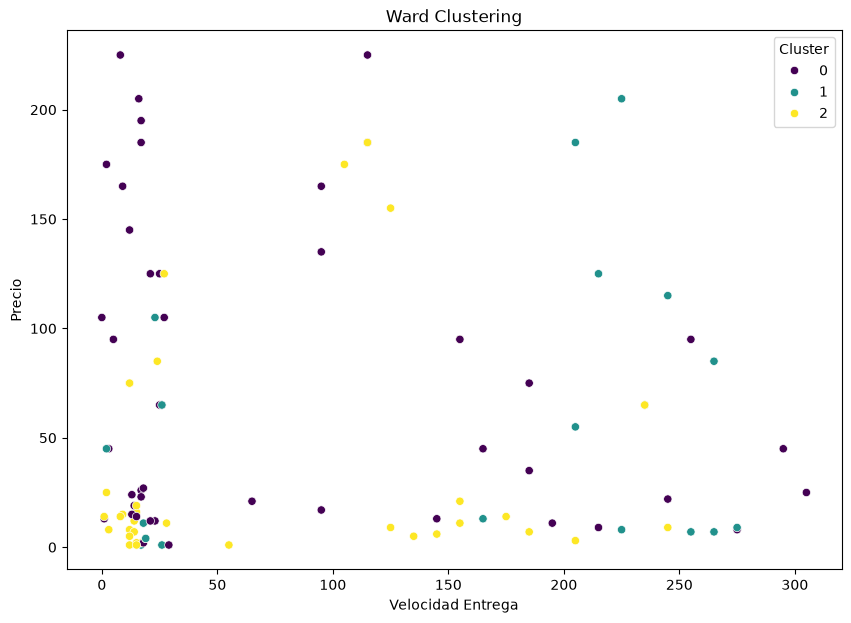

In [3]:

# Perform Ward clustering
ward = AgglomerativeClustering(n_clusters=3, linkage='ward')
clusters = ward.fit_predict(scaled_features)

# Add the cluster labels to the dataframe
dataframe['Cluster'] = clusters

# Visualize the clusters
plt.figure(figsize=(10, 7))
sns.scatterplot(data=dataframe, x='Velocidad Entrega', y='Precio', hue='Cluster', palette='viridis')
plt.title('Ward Clustering')
plt.show()

Heights of the last 5 merges: [ 8.77  8.98 10.15 13.4  13.95]
Jumps between them: [0.21 1.18 3.25 0.55]


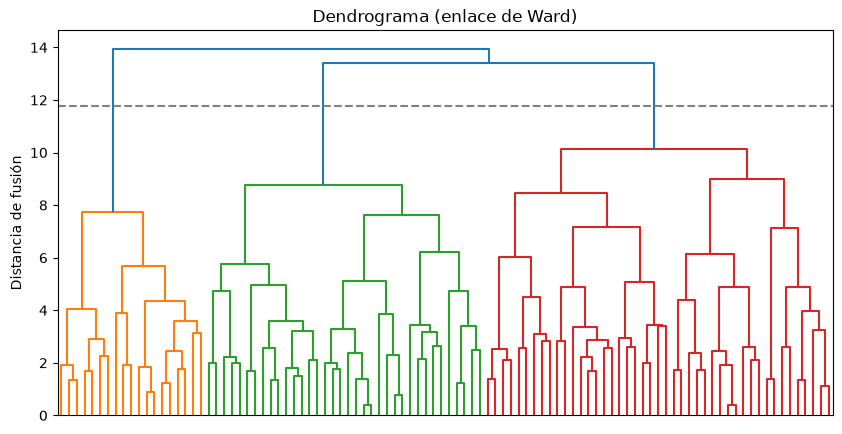

In [4]:
# Dendrogram (Ward linkage) to choose the number of clusters
from scipy.cluster.hierarchy import linkage, dendrogram

linkage_matrix = linkage(scaled_features, method='ward')

# Heights of the last merges: the largest jump marks a natural place to cut the tree
last_heights = linkage_matrix[-5:, 2]
print("Heights of the last 5 merges:", last_heights.round(2))
print("Jumps between them:", (last_heights[1:] - last_heights[:-1]).round(2))

cut_height = (linkage_matrix[-3, 2] + linkage_matrix[-2, 2]) / 2  # between the merges that leave 3 and 2 clusters
plt.figure(figsize=(10, 5))
dendrogram(linkage_matrix, no_labels=True, color_threshold=cut_height)
plt.axhline(cut_height, color='gray', linestyle='--')
plt.title('Dendrograma (enlace de Ward)')
plt.ylabel('Distancia de fusión')
plt.show()

El salto más grande entre fusiones consecutivas ocurre entre la que deja 3 grupos y la que deja 2, así que cortar el dendrograma en la línea punteada da 3 clústeres. Eso justifica el `n_clusters=3` usado arriba.

### Tarea 3. Ubicar a las tres clientas

In [5]:
salome = dataframe[dataframe['Consumidor'] == 'Salome']
salome 

,Consumidor,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,Cluster
81,Salome,17,23,275,41,4,44,315,28,32,0


In [6]:
salome_cluster = salome['Cluster'].values[0]
salome_cluster

np.int64(0)

In [7]:
similiar_to_salome = dataframe[dataframe['Cluster'] == salome_cluster]
similiar_to_salome.to_csv('similares-a-salome.csv', index=False)

In [8]:
# Create a function with the code to find similar consumers
def get_similar_consumers(dataframe, consumer):
  try:
    cluster = dataframe[dataframe['Consumidor'] == consumer]['Cluster'].values[0]
    similar_consumers = dataframe[dataframe['Cluster'] == cluster]
    return similar_consumers
  except IndexError:
    return 'Consumer not found in the dataframe'

salome = get_similar_consumers(dataframe, 'Salome')
salome.equals(similiar_to_salome)

True

In [9]:
salome['Cluster'].unique()

array([0])

In [10]:
stephania = get_similar_consumers(dataframe, 'Stephania')
stephania['Cluster'].unique()

array([1])

In [11]:
lydia = get_similar_consumers(dataframe, 'Lydia')
lydia['Cluster'].unique()

array([2])

### Tarea 4. Recomendar productos

In [12]:
# Recommend to each client the purchases of the most similar consumer in the same cluster
# (smallest Euclidean distance in the standardized feature space)
import numpy as np

def most_similar_consumer(dataframe, consumer):
    idx = dataframe.index[dataframe['Consumidor'] == consumer][0]
    same_cluster = dataframe.index[(dataframe['Cluster'] == dataframe.loc[idx, 'Cluster']) & (dataframe.index != idx)]
    distances = np.linalg.norm(scaled_features[same_cluster] - scaled_features[idx], axis=1)
    order = np.argsort(distances)[:3]
    return [(dataframe.loc[same_cluster[k], 'Consumidor'], float(round(distances[k], 2))) for k in order]

for consumer in ['Salome', 'Stephania', 'Lydia']:
    print(consumer, '->', most_similar_consumer(dataframe, consumer))

Salome -> [('Magdalyna', 2.77), ('Henry', 2.97), ('Susanna', 3.0)]
Stephania -> [('Judith', 1.4), ('Helen', 1.91), ('Maura', 2.24)]
Lydia -> [('Lubomyr', 1.51), ('Fialka', 1.68), ('Edward', 1.92)]


### Conclusiones

A partir de nuestro analisis de clustering jerarquico, determinamos que ninguna de las clientas recibiría las mismas recomendaciones de productos, ya que cada una de ellas pertenece a un cluster diferente. Dentro de cada cluster, el consumidor más parecido (menor distancia con las variables estandarizadas) es la mejor referencia:

- Recomendaría a **Salomé** los mismos productos que compró **Magdalyna** (y, como alternativas, los de Henry y Susanna).
- Recomendaría a **Stephanía** los mismos productos que compró **Judith** (alternativas: Helen y Maura).
- Recomendaría a **Lydia** los mismos productos que compró **Lubomyr** (alternativas: Fialka y Edward).

La lista completa de consumidores del cluster de Salomé está en el archivo `similares-a-salome.csv`.

**Revisión posterior (2026-10):** se añadió el dendrograma que justifica elegir 3 clústeres y una celda que identifica, para cada clienta, al consumidor más parecido de su cluster, de modo que las conclusiones nombran clientes concretos como pide el enunciado; también se corrigió el nombre del archivo CSV citado. El PDF conserva la versión entregada.